In [74]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, accuracy_score
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import AdaBoostClassifier
from sklearn.ensemble import VotingClassifier
from sklearn.model_selection import cross_val_score

## Data Visualisation

- **`titanic_train.csv`**: Contains details of 1047 passengers, including whether they survived (the ground truth).
- **`titanic_test.csv`**: Features details of 256 passengers. You will predict the survival of these passengers based on patterns from the training dataset.

We load data from two CSV files into Pandas dataframes and display the first rows of both datasets to visualise and understand their structure.

In [75]:
file_train = 'titanic_train.csv'
file_test = 'titanic_test.csv'

# Read CSV files
df_train = pd.read_csv(file_train)
df_test = pd.read_csv(file_test)

In [76]:
display(df_train.head())
display(df_test.head())

,pclass,survived,name,sex,age,sibsp,parch,ticket,fare,cabin,embarked,boat,body,homedest
0,3,0,"Stoytcheff, Mr. Ilia",male,19,0,0,349205,7.8958,?,S,?,?,?
1,3,0,"Kink, Mr. Vincenz",male,26,2,0,315151,8.6625,?,S,?,?,?
2,3,0,"Sivic, Mr. Husein",male,40,0,0,349251,7.8958,?,S,?,?,?
3,2,1,"Brown, Miss. Edith Eileen",female,15,0,2,29750,39,?,S,14,?,"Cape Town, South Africa / Seattle, WA"
4,1,1,"Goldenberg, Mrs. Samuel L (Edwiga Grabowska)",female,?,1,0,17453,89.1042,C92,C,5,?,"Paris, France / New York, NY"


,pclass,survived,name,sex,age,sibsp,parch,ticket,fare,cabin,embarked,boat,body,homedest
0,3,0,"Nysveen, Mr. Johan Hansen",male,61,0,0,345364,6.2375,?,S,?,?,?
1,1,0,"Brandeis, Mr. Emil",male,48,0,0,PC 17591,50.4958,B10,C,?,208,"Omaha, NE"
2,2,0,"Giles, Mr. Ralph",male,24,0,0,248726,13.5000,?,S,?,297,"West Kensington, London"
3,3,0,"Risien, Mr. Samuel Beard",male,?,0,0,364498,14.5000,?,S,?,?,?
4,3,0,"Toufik, Mr. Nakli",male,?,0,0,2641,7.2292,?,C,?,?,?


In [77]:
# Count the number of entries in each dataset
count_train = df_train.shape[0]
count_test = df_test.shape[0]

print("Number of people in the training dataset:", count_train)
print("Number of people in the test dataset:", count_test)

Number of people in the training dataset: 1047
Number of people in the test dataset: 262


We clean up to identify missing values so that we can handle them properly later on.

In [78]:
# Replace ‘?’ with NaN in the training and test datasets
df_train.replace('?', np.nan, inplace=True)
df_test.replace('?', np.nan, inplace=True)

# Count the number of NaN values in each column
nan_count_train = df_train.isna().sum()
nan_count_test = df_test.isna().sum()

# Show NaN count for the training dataset
display("NaN counts in training data:")
display(nan_count_train)

# Show the NaN count for the test dataset
display("\nNaN counts in test data:")
display(nan_count_test)

'NaN counts in training data:'

pclass        0
survived      0
name          0
sex           0
age         224
sibsp         0
parch         0
ticket        0
fare          1
cabin       814
embarked      1
boat        659
body        956
homedest    464
dtype: int64

'\nNaN counts in test data:'

pclass        0
survived      0
name          0
sex           0
age          39
sibsp         0
parch         0
ticket        0
fare          0
cabin       200
embarked      1
boat        164
body        232
homedest    100
dtype: int64

## Data Processing

We prepare the data for use in machine learning models. This ensures that missing values are handled, categorical columns are converted to numerical values, new features are created and irrelevant columns are removed. This improves data quality and makes training easier.

We convert the 'age' column to float data so that we can handle errors by merging any NaNs. We then fill in the missing values with the average of the existing values in the column.

In [79]:
# Convert column ‘age’ to numeric, errors=‘coerce’ converts non-convertible values to NaN
df_train['age'] = pd.to_numeric(df_train['age'], errors='coerce')
df_test['age'] = pd.to_numeric(df_test['age'], errors='coerce')

# Now fill NaN with the average value in the column ‘age’
df_train['age'].fillna(df_train['age'].mean(), inplace=True)
df_test['age'].fillna(df_test['age'].mean(), inplace=True)

We convert the values in the ‘sex’ column to numeric values: we replace the values ‘male’ with 1 and ‘female’ with 0.

We replace the missing values of ‘embarked’ with 1.

In [80]:
# Map ‘male’ to 1 and ‘female’ to 0 in the gender columns
df_train['sex'] = df_train['sex'].map({'male': 1, 'female': 0})
df_test['sex'] = df_test['sex'].map({'male': 1, 'female': 0})

# Replace ‘?’ with 1 in the ‘embarked’ column of both datasets
df_train['embarked'].fillna(1, inplace=True)
df_test['embarked'].fillna(1, inplace=True)

We map the ports of shipment by converting categorical values to numbers and replace missing values with 1.

In [81]:
# Map the ports of embarkation in the ‘embarked’ columns
port_mapping = {'C': 0, 'Q': 1, 'S': 2}
df_train['embarked'] = df_train['embarked'].map(port_mapping)
df_test['embarked'] = df_test['embarked'].map(port_mapping)

# Replace ‘?’ with 1 in the ‘embarked’ column of both datasets
df_train['embarked'].fillna(1, inplace=True)
df_test['embarked'].fillna(1, inplace=True)

We replace NaN values in the ‘boat’ column with 0.

We convert all values in the ‘boat’ column to a numeric type, if a value in the column is not convertible, it will be converted to NaN due to errors=‘coerce’.

In [82]:
# Replace NaN with 0 in the ‘boat’ column of the training and test datasets
df_train['boat'].fillna(0, inplace=True)
df_test['boat'].fillna(0, inplace=True)

# Convert the ‘boat’ column to numeric, ensuring that all values are treated as numbers
df_train['boat'] = pd.to_numeric(df_train['boat'], errors='coerce')
df_test['boat'] = pd.to_numeric(df_test['boat'], errors='coerce')

We replace the NaN values in the ‘body’ column with 0 and convert the values to numerical.

We convert the value in ‘body’ to 1 if the corresponding value in ‘boat’ is not 0.

In [83]:
# Replace NaN with 0 in the ‘body’ column of the training and test datasets
df_train['body'].fillna(0, inplace=True)
df_test['body'].fillna(0, inplace=True)

# Convert the ‘body’ column to numeric, ensuring that all values are treated as numbers
df_train['body'] = pd.to_numeric(df_train['body'], errors='coerce')
df_test['body'] = pd.to_numeric(df_test['body'], errors='coerce')

# Convert values in ‘boat’ to 1 if different from 0
df_train['body'] = df_train['boat'].apply(lambda x: 1 if x != 0 else 0)
df_test['body'] = df_test['boat'].apply(lambda x: 1 if x != 0 else 0)

We convert the column ‘fare’ to numeric type. Any non-numeric values, such as ‘?’, are converted to NaN.

We calculate the mean of ‘fare’ and fill in the NaN values with it, thus allowing for a dataset with no missing values in that column.

We use the MinMaxScaler to scale the values of ‘fare’ in a range between 0 and 1.

In [84]:
# First, convert ‘fare’ to numeric, replacing ‘?’ with NaN to allow for calculations
df_train['fare'] = pd.to_numeric(df_train['fare'], errors='coerce')
df_test['fare'] = pd.to_numeric(df_test['fare'], errors='coerce')

# Calculate the average fare excluding NaN
fare_mean_train = df_train['fare'].mean()
fare_mean_test = df_test['fare'].mean()

# Fill NaN with the calculated average
df_train['fare'].fillna(fare_mean_train, inplace=True)
df_test['fare'].fillna(fare_mean_test, inplace=True)

# Scale the ‘fare’ column using MinMaxScaler to adjust values between 0 and 1
scaler = MinMaxScaler()

# Set the scaler only on the training data and then transform both sets
df_train['fare_scaled'] = scaler.fit_transform(df_train[['fare']])
df_test['fare_scaled'] = scaler.transform(df_test[['fare']])

We created a new feature called ‘family_size’, which represents the size of the family on board.

In [85]:
# Feature engineering: Create a new feature 'family_size'
df_train['family_size'] = df_train['sibsp'] + df_train['parch']
df_test['family_size'] = df_test['sibsp'] + df_test['parch']

We create a new column called ‘Marital_Status’, which indicates the likely marital status of each person based on the title in their name and assign specific numeric values according to the title.

In [86]:
# Function to determine marital status based on title and return specific numeric values
def determine_marital_status_numeric(name):
    if 'Miss' in name:
        return 0  # Single
    elif 'Mrs' in name:
        return 1  # Married
    elif 'Mr' in name:
        return 3  # Married, assuming by default that all the ‘Mr’ are married
    elif 'Ms' in name:
        return 4  # Single, ‘Ms’ can be used for single women or women of unspecified marital status
    else:
        return -1   # Returns None if it does not meet the above criteria, which becomes NaN

# Apply the function to each entry in the ‘Name’ column for the training and test datasets
df_train['Marital_Status'] = df_train['name'].apply(determine_marital_status_numeric)
df_test['Marital_Status'] = df_test['name'].apply(determine_marital_status_numeric)

We created a new column that classifies passengers into different age ranges.

In [87]:
# Defining the limits of the age ranges
bins = [0, 10, 20, 35, 50, float('inf')]

# Labels for age groups
labels = [0, 1, 2, 3, 4]

# Create the column ‘Age_Group’ in the training and test DataFrames
df_train['Age_Group'] = pd.cut(df_train['age'], bins=bins, labels=labels, right=False)
df_test['Age_Group'] = pd.cut(df_test['age'], bins=bins, labels=labels, right=False)

We clean the datasets by removing columns that do not provide valuable information for the model.

In [88]:
# Dropping columns that are unlikely to contribute to the model
train_data_cleaned = df_train.drop(columns=['name', 'ticket', 'cabin', 'homedest'])
test_data_cleaned = df_test.drop(columns=['name', 'ticket', 'cabin', 'homedest'])

We visualise the first lines

In [89]:
display(train_data_cleaned.head())
display(test_data_cleaned.head())

,pclass,survived,sex,age,sibsp,parch,fare,embarked,boat,body,fare_scaled,family_size,Marital_Status,Age_Group
0,3,0,1,19.000000,0,0,7.8958,2.0,0.0,0,0.015412,0,3,1
1,3,0,1,26.000000,2,0,8.6625,2.0,0.0,0,0.016908,2,3,2
2,3,0,1,40.000000,0,0,7.8958,2.0,0.0,0,0.015412,0,3,3
3,2,1,0,15.000000,0,2,39.0000,2.0,14.0,1,0.076123,2,0,1
4,1,1,0,29.646719,1,0,89.1042,0.0,5.0,1,0.173920,1,1,2


,pclass,survived,sex,age,sibsp,parch,fare,embarked,boat,body,fare_scaled,family_size,Marital_Status,Age_Group
0,3,0,1,61.000000,0,0,6.2375,2.0,0.0,0,0.012175,0,3,4
1,1,0,1,48.000000,0,0,50.4958,0.0,0.0,0,0.098561,0,3,3
2,2,0,1,24.000000,0,0,13.5000,2.0,0.0,0,0.026350,0,3,2
3,3,0,1,30.746263,0,0,14.5000,2.0,0.0,0,0.028302,0,3,2
4,3,0,1,30.746263,0,0,7.2292,0.0,0.0,0,0.014110,0,3,2


We check that there are no missing values in the data after all the transformations and replacements.

In [90]:
# Replace ‘?’ with NaN in the training and test datasets
train_data_cleaned.replace('?', np.nan, inplace=True)
test_data_cleaned.replace('?', np.nan, inplace=True)

# Count the number of NaN values (originally ‘?’) in each column
nan_count_train = train_data_cleaned.isna().sum()
nan_count_test = test_data_cleaned.isna().sum()

# Show NaN count for the training dataset
display("NaN counts in training data:")
display(nan_count_train)

# Show the NaN count for the test dataset
display("\nNaN counts in test data:")
display(nan_count_test)

'NaN counts in training data:'

pclass             0
survived           0
sex                0
age                0
sibsp              0
parch              0
fare               0
embarked           0
boat              67
body               0
fare_scaled        0
family_size        0
Marital_Status     0
Age_Group          0
dtype: int64

'\nNaN counts in test data:'

pclass             0
survived           0
sex                0
age                0
sibsp              0
parch              0
fare               0
embarked           0
boat              21
body               0
fare_scaled        0
family_size        0
Marital_Status     0
Age_Group          0
dtype: int64

We check for non-numeric values in the column ‘ship’ to ensure that all columns we use in the model contain numeric data.
1) We identify the non-numeric values in the 'boat' column.
2) We define a function that replaces these values with zeros.
3) We apply this function to the two sets of data and check

In [91]:
import pandas as pd

def encontrar_filas_no_numericos(df, columna='boat'):
    """
    Replace the value in the ‘boat’ column with 0 for the specific rows provided.

    Parameters:
    df (pd.DataFrame): The input DataFrame.
    rows (list): List of row indices where the value in the ‘boat’ column shall be replaced by 0.

    Return:
    pd.DataFrame: The DataFrame with the values of ‘boat’ in the indicated rows replaced by 0.
    """
    # Usar pd.to_numeric para identificar valores no numéricos; errors='coerce' convierte no numéricos a NaN
    mask_no_numericos = pd.to_numeric(df[columna], errors='coerce').isna()
    
    # Obtener los índices (números de fila) donde los valores en 'boat' no son numéricos
    indices_no_numericos = df.index[mask_no_numericos].tolist()
    
    return indices_no_numericos

# Encontrar las filas no numéricas en la columna 'boat' en df_train
filas_no_numericos_train = encontrar_filas_no_numericos(df_train, 'boat')
print(f"Números de filas no numéricas en 'boat' en df_train: {filas_no_numericos_train}")

# Encontrar las filas no numéricas en la columna 'boat' en df_test
filas_no_numericos_test = encontrar_filas_no_numericos(df_test, 'boat')
print(f"Números de filas no numéricas en 'boat' en df_test: {filas_no_numericos_test}")


Números de filas no numéricas en 'boat' en df_train: [8, 11, 18, 27, 34, 48, 127, 157, 158, 172, 184, 185, 189, 200, 209, 223, 266, 289, 295, 327, 358, 371, 381, 389, 409, 417, 438, 452, 453, 455, 456, 460, 462, 464, 471, 495, 498, 557, 567, 568, 588, 590, 593, 625, 626, 637, 638, 639, 687, 700, 702, 704, 733, 734, 747, 775, 783, 784, 797, 823, 837, 878, 903, 948, 959, 1027, 1034]
Números de filas no numéricas en 'boat' en df_test: [6, 17, 18, 19, 34, 36, 40, 54, 56, 57, 73, 92, 98, 113, 126, 146, 155, 158, 182, 238, 242]


In [92]:
def reemplazar_filas_boat_con_cero(df, filas):
    """
    Replace the value in the ‘boat’ column with 0 for the specific rows provided.

    Parameters:
    df (pd.DataFrame): The input DataFrame.
    rows (list): List of row indices where the value in the ‘boat’ column shall be replaced by 0.

    Return:
    pd.DataFrame: The DataFrame with the values of ‘boat’ in the indicated rows replaced by 0.
    """
    # Scroll through the identified rows and replace the value in the ‘boat’ column with 0
    for fila in filas:
        df.at[fila, 'boat'] = 0
    
    return df

# List of rows with non-numeric values in column ‘boat’ in df_train
filas_no_numericos_train = [8, 11, 18, 27, 34, 48, 127, 157, 158, 172, 184, 185, 189, 200, 209, 223, 266, 289, 295, 327, 
                            358, 371, 381, 389, 409, 417, 438, 452, 453, 455, 456, 460, 462, 464, 471, 495, 498, 557, 
                            567, 568, 588, 590, 593, 625, 626, 637, 638, 639, 687, 700, 702, 704, 733, 734, 747, 775, 
                            783, 784, 797, 823, 837, 878, 903, 948, 959, 1027, 1034]

# Apply the function to replace with 0 in the indicated rows
train_data_cleaned = reemplazar_filas_boat_con_cero(train_data_cleaned, filas_no_numericos_train)

# Check if the values have been replaced correctly
print(train_data_cleaned.loc[filas_no_numericos_train, 'boat'])


8       0.0
11      0.0
18      0.0
27      0.0
34      0.0
       ... 
903     0.0
948     0.0
959     0.0
1027    0.0
1034    0.0
Name: boat, Length: 67, dtype: float64


In [93]:
def reemplazar_filas_boat_con_cero(df, filas):
    """
    Replace the value in the ‘boat’ column with 0 for the specific rows provided.

    Parameters:
    df (pd.DataFrame): The input DataFrame.
    rows (list): List of row indices where the value in the ‘boat’ column shall be replaced by 0.

    Return:
    pd.DataFrame: The DataFrame with the values of ‘boat’ in the indicated rows replaced by 0.
    """
    # Scroll through the identified rows and replace the value in the ‘boat’ column with 0
    for fila in filas:
        df.at[fila, 'boat'] = 0
    
    return df

# List of rows with non-numeric values in the ‘boat’ column for the second set
filas_no_numericos_test = [6, 17, 18, 19, 34, 36, 40, 54, 56, 57, 73, 92, 98, 113, 126, 146, 155, 158, 182, 238, 242]

# Apply the function to replace with 0 in the rows indicated in df_test
test_data_cleaned = reemplazar_filas_boat_con_cero(test_data_cleaned, filas_no_numericos_test)

# Check if the values have been replaced correctly
print(test_data_cleaned.loc[filas_no_numericos_test, 'boat'])


6      0.0
17     0.0
18     0.0
19     0.0
34     0.0
36     0.0
40     0.0
54     0.0
56     0.0
57     0.0
73     0.0
92     0.0
98     0.0
113    0.0
126    0.0
146    0.0
155    0.0
158    0.0
182    0.0
238    0.0
242    0.0
Name: boat, dtype: float64


In [94]:
# Convert values in ‘boat’ to 1 if different from 0
train_data_cleaned['boat'] = train_data_cleaned['boat'].apply(lambda x: 1 if x != 0 else 0)
test_data_cleaned['boat'] = test_data_cleaned['boat'].apply(lambda x: 1 if x != 0 else 0)

We clean the data from the **`train_data_cleaned`** and **`test_data_cleaned`** sets.

In [95]:
# Replace ‘?’ with NaN in the training and test datasets
train_data_cleaned.replace('?', np.nan, inplace=True)
test_data_cleaned.replace('?', np.nan, inplace=True)

# Count the number of NaN values in each column
nan_count_train = train_data_cleaned.isna().sum()
nan_count_test = test_data_cleaned.isna().sum()

# Show NaN count for the training dataset
display("NaN counts in training data:")
display(nan_count_train)

# Show the NaN count for the test dataset
display("\nNaN counts in test data:")
display(nan_count_test)

'NaN counts in training data:'

pclass            0
survived          0
sex               0
age               0
sibsp             0
parch             0
fare              0
embarked          0
boat              0
body              0
fare_scaled       0
family_size       0
Marital_Status    0
Age_Group         0
dtype: int64

'\nNaN counts in test data:'

pclass            0
survived          0
sex               0
age               0
sibsp             0
parch             0
fare              0
embarked          0
boat              0
body              0
fare_scaled       0
family_size       0
Marital_Status    0
Age_Group         0
dtype: int64

## Clean Data Visulisation

We visualise the correlation matrix of **`train_data_cleaned`**, facilitating visual compression of the relationships between numerical variables.

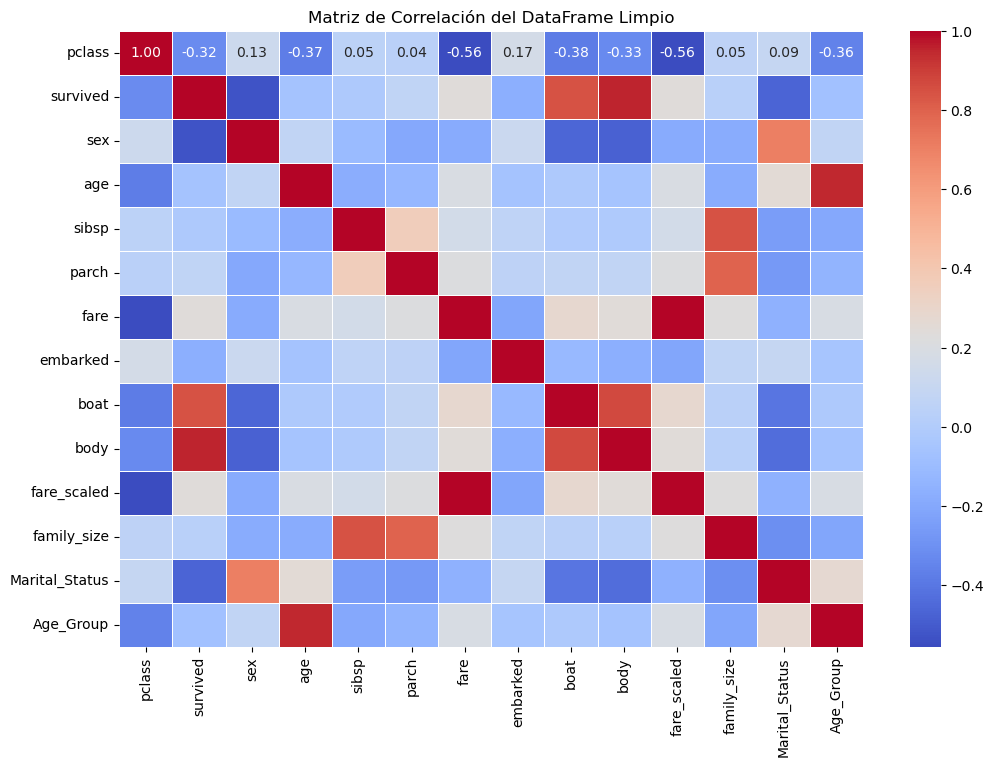

In [96]:
# Calculate the correlation matrix
correlation_matrix = train_data_cleaned.corr()

# Set the size of the figure
plt.figure(figsize=(12, 8))

# Create a heatmap using seaborn to visualise the correlation matrix
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=.5)

# Title and tags
plt.title('Matriz de Correlación del DataFrame Limpio')
plt.show()

There is a negative correlation between passenger class (pclass) and fare paid (fare), indicating that higher classes tend to pay higher fares.

There is also a strong correlation between survived (survived) and being on a boat (boat), suggesting that passengers on boats were significantly more likely to survive. Additionally, being female is positively associated with survival, reflecting the ‘women and children first’ policy implemented during the disaster.

On the other hand, embarked port (embarked) shows little impact on survival but does affect fare and class, possibly due to differences in routes and fares associated with each port.

We create a boxplot to visualise the distribution of values in the age column, allowing us to observe the distribution and possible outliers in the age data.

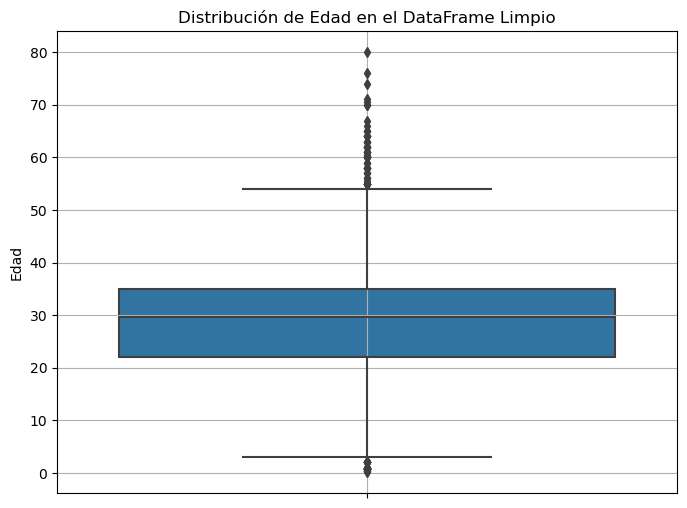

In [97]:
# Create a boxplot for the column ‘age’
plt.figure(figsize=(8, 6))  # Set the size of the figure
sns.boxplot(y=train_data_cleaned['age'])
plt.title('Distribución de Edad en el DataFrame Limpio')
plt.ylabel('Edad')
plt.grid(True)
plt.show()

Most of the ages are between 20 and 40 years, with a median close to 30 years.
There are some outliers, especially at the high end (over 60 years) and at the low end (close to or below 0), which could be data entry errors or exceptional cases.

We group the data by gender and survival, count the number of survivors and non-survivors in each group, and generate a stacked bar chart showing this information.

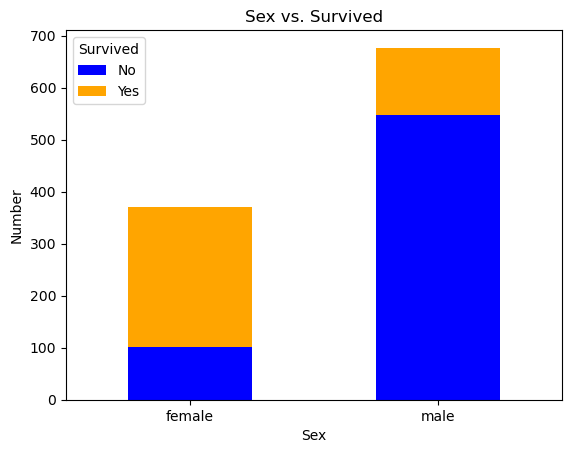

In [98]:
def compare_sex_survival(df):
    # Create a DataFrame that counts the number of passengers by gender and survival
    resumen = df.groupby(['sex', 'survived']).size().unstack().fillna(0)
    
    # Map back numerical values to categories for the graph
    resumen.index = ['female', 'male'] if 'sex' in df.columns and df['sex'].dtype == 'int64' else resumen.index
    resumen.columns = ['No', 'Sí'] if 'survived' in df.columns and df['survived'].dtype == 'int64' else resumen.columns

    # Graphic
    resumen.plot(kind='bar', stacked=True, color=['blue', 'orange'])
    plt.title('Sex vs. Survived')
    plt.xlabel('Sex')
    plt.ylabel('Number')
    plt.xticks(rotation=0)  # Avoid rotation of the X-axes
    plt.legend(title='Survived', labels=['No', 'Yes'])

    plt.show()

# Call the function with the clean DataFrame
compare_sex_survival(train_data_cleaned)

This graph shows a striking difference in survival rates between men and women:

Women were more likely to survive, while most men did not. This is due to the 'women and children first' policy.

We add a column indicating whether the passenger was rescued on a boat or not, then calculate and display the probability of survival based on this condition.

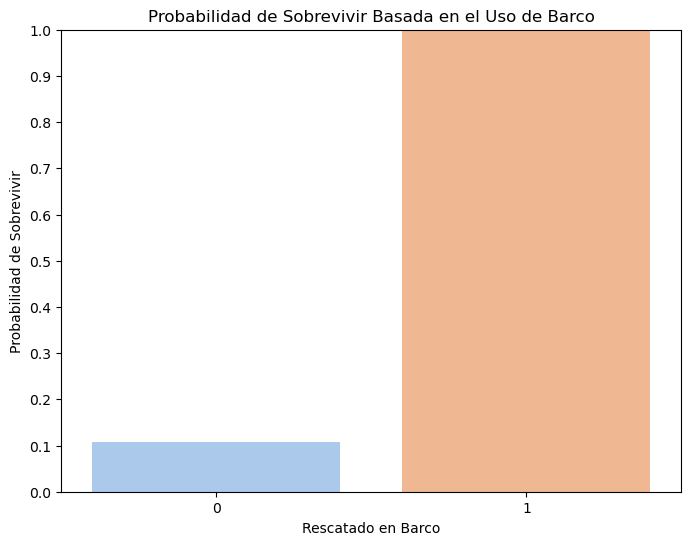

In [99]:
# Calculate the probability of survival for boat rescued vs. non-rescued
survival_rates = train_data_cleaned.groupby('boat')['survived'].mean()

# Graphic
plt.figure(figsize=(8, 6))
sns.barplot(x=survival_rates.index, y=survival_rates.values, palette='pastel')

# Customise Y-axis ticks
plt.title('Probabilidad de Sobrevivir Basada en el Uso de Barco')
plt.xlabel('Rescatado en Barco')
plt.ylabel('Probabilidad de Sobrevivir')
plt.ylim(0, 1)
plt.yticks([i * 0.1 for i in range(11)])
plt.show()

It helps us to observe whether being rescued on a boat affected the probability of survival:

The 'Yes' bar is higher than the 'No' bar, suggesting that passengers rescued on boats had a higher chance of survival.
This makes sense as the water temperature was very low.

We calculate and visualise the survival probability of passengers according to family size.

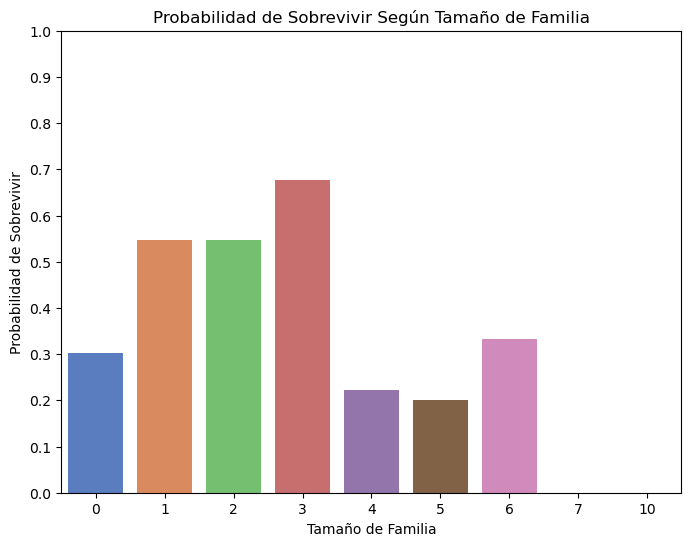

In [100]:
# Calculate the probability of survival for each family size
survival_by_family_size = train_data_cleaned.groupby('family_size')['survived'].mean()

# Graphic
plt.figure(figsize=(8, 6))
sns.barplot(x=survival_by_family_size.index, y=survival_by_family_size.values, palette='muted')

# Customise the chart
plt.title('Probabilidad de Sobrevivir Según Tamaño de Familia')
plt.xlabel('Tamaño de Familia')
plt.ylabel('Probabilidad de Sobrevivir')
plt.ylim(0, 1)
plt.yticks([i * 0.1 for i in range(11)])
plt.xticks(rotation=0)
plt.show()

The graph suggests that the size of the family affected the likelihood of survival. Passengers travelling in small groups (2-3 members) had a better chance of survival, while those travelling alone or in large families faced greater difficulties.

We created the violin graph to visualise the distribution of fares paid according to passenger survival, allowing us to see how the amount of money someone paid might have influenced their chances of survival.

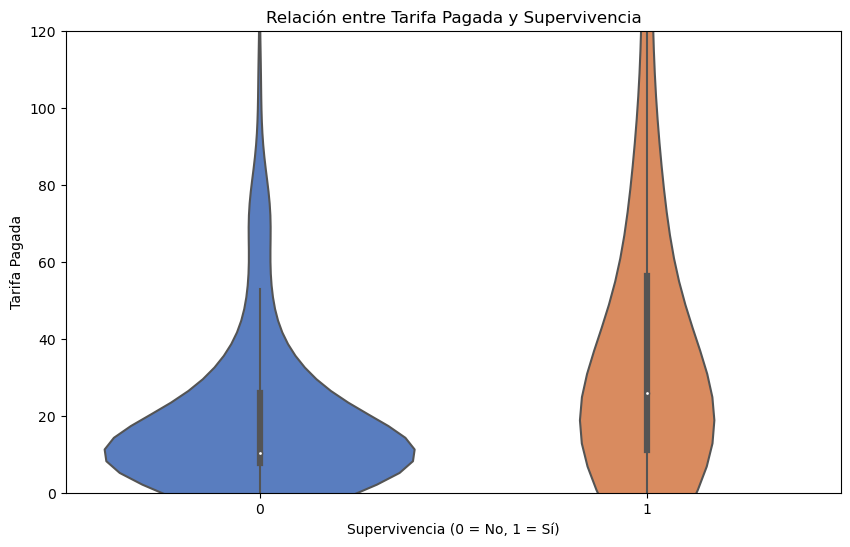

In [101]:
# Create the violin chart to see the distribution of fares according to survival
plt.figure(figsize=(10, 6))
sns.violinplot(x='survived', y='fare', data=train_data_cleaned, palette='muted')

# Customisation of the chart
plt.title('Relación entre Tarifa Pagada y Supervivencia')
plt.xlabel('Supervivencia (0 = No, 1 = Sí)')
plt.ylabel('Tarifa Pagada')
plt.ylim(0, train_data_cleaned['fare'].quantile(0.95))  # Limit the Y-axis to the 95th percentile to avoid extreme values

plt.show()

The violin plot reveals that passengers who paid lower fares (around 10-20) had a lower probability of survival, as seen in the higher density in the group of those who did not survive. 

On the other hand, those who paid higher fares (above 50) show a higher survival rate. This suggests a correlation between higher fees and a higher probability of survival, probably linked to socio-economic status and access to better resources such as lifeboats.

We created a histogram showing the distribution of passengers by age group and the survival rate.

c:\Users\hbenj\OneDrive\Escritorio\Anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


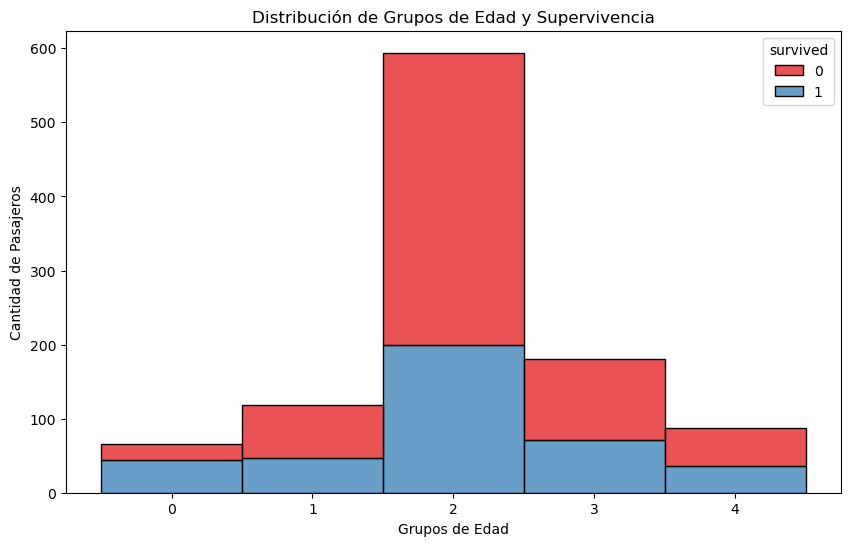

In [102]:
plt.figure(figsize=(10, 6))

# Use hue=‘survived’ to differentiate between those who survived (1) and those who didn't (0)
sns.histplot(data=train_data_cleaned, x='Age_Group', hue='survived', multiple='stack', palette='Set1')

# Customisation of the chart
plt.title('Distribución de Grupos de Edad y Supervivencia')
plt.xlabel('Grupos de Edad')
plt.ylabel('Cantidad de Pasajeros')
plt.show()

The graph shows how survival on the Titanic varied by age. Young adults (group 2) were the group with the highest number of survivors and also the highest number of fatalities. Children, on the other hand, appear to have had a higher survival rate than adults.

This suggests that age was an important factor in the likelihood of survival, with children receiving priority treatment.

We remove columns that do not contribute to the model

In [114]:
train_data_cleaned1 = train_data_cleaned.drop(columns=['age', 'fare', 'sibsp', 'parch','Age_Group', 'family_size', 'embarked'])
test_data_cleaned1 = test_data_cleaned.drop(columns=['age', 'fare', 'sibsp', 'parch', 'Age_Group', 'family_size', 'embarked'])

## Training the system

We prepare the data to train the model to predict survival.

In [115]:
# Ensure that ‘Survived’ is the target column and is excluded from training
X_train = train_data_cleaned1.drop('survived', axis=1)
y_train = train_data_cleaned1['survived']
X_test = test_data_cleaned1.drop('survived', axis=1)
y_test = test_data_cleaned1['survived']

We implement an exhaustive search process to find the best hyperparameters of a decision tree model.

We therefore explore combinations of the maximum tree depth (max_depth), the minimum number of samples to split a node (min_samples_split), the minimum number of samples in a leaf (min_samples_leaf), and the splitting criterion (criterion), evaluating each according to its accuracy on a test set.

Gini Impurity (Gini)

Measures the chance of incorrect classification of a randomly chosen element if it were randomly labeled according to the class distribution in the dataset.


Entropy (Information Gain)

Measures the randomness or impurity in the dataset, aiming to maximize information gain.

In [116]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# Define the base Decision Tree model
dt_model = DecisionTreeClassifier(random_state=42)

# Define the hyperparameter grid
param_grid = {
    'max_depth': [1, 3, 5, 10, 15, None],  # Maximum tree depth
    'min_samples_split': [2, 4, 6, 8, 10, 12, 14],  # Minimum number of samples required to split a node
    'min_samples_leaf': [1, 2, 3, 4, 5, 6, 7, 8],  # Minimum number of samples required at a leaf node
    'criterion': ['gini', 'entropy']  # Function to measure the quality of a split
}

# Configure GridSearchCV with cross-validation
grid_search_dt = GridSearchCV(estimator=dt_model, param_grid=param_grid, cv=5, scoring='accuracy', verbose=1, n_jobs=-1)

# Train the model using GridSearchCV on the training set
grid_search_dt.fit(X_train, y_train)

# Best hyperparameters found
print("Best hyperparameters found:", grid_search_dt.best_params_)
print("Best cross-validation accuracy:", grid_search_dt.best_score_)

# Get the best model from grid search
best_model = grid_search_dt.best_estimator_

# Predict on the test set with the best model
y_pred = best_model.predict(X_test)

# Model evaluation
print("Accuracy on the test set:", accuracy_score(y_test, y_pred))
print("Confusion matrix:")
print(confusion_matrix(y_test, y_pred))
print("Classification report:")
print(classification_report(y_test, y_pred))


Fitting 5 folds for each of 672 candidates, totalling 3360 fits
Best hyperparameters found: {'criterion': 'gini', 'max_depth': 1, 'min_samples_leaf': 1, 'min_samples_split': 2}
Best cross-validation accuracy: 0.9789929368876737
Accuracy on the test set: 0.9618320610687023
Confusion matrix:
[[157   3]
 [  7  95]]
Classification report:
              precision    recall  f1-score   support

           0       0.96      0.98      0.97       160
           1       0.97      0.93      0.95       102

    accuracy                           0.96       262
   macro avg       0.96      0.96      0.96       262
weighted avg       0.96      0.96      0.96       262



The script starts by setting up a RandomForestClassifier with specified hyperparameters such as tree depth, number of trees, and node sample requirements. It uses GridSearchCV with 5-fold cross-validation to find the best hyperparameters based on accuracy, and then it retrieves the best-performing model. Additionally, cross_val_score is employed for an extra round of cross-validation to confirm model stability. Finally, the script tests the optimized model on a separate dataset, reports its accuracy, and provides a detailed classification analysis, ensuring the model is robust and performs well on unseen data.

In [110]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV, cross_val_score
from sklearn.metrics import accuracy_score, classification_report
import numpy as np

# Configure the Random Forest classifier
random_forest = RandomForestClassifier(random_state=42)

# Define the parameter grid
param_grid = {
    'max_depth': [10, 20, 30, None],  # Maximum depth of the trees
    'n_estimators': [10, 50, 100, 200],  # Number of trees in the forest
    'min_samples_split': [2, 5, 10],  # Minimum number of samples required to split an internal node
    'min_samples_leaf': [1, 2, 4]  # Minimum number of samples required to be at a leaf node
}

# Configure GridSearchCV with cross-validation
grid_search_rf = GridSearchCV(estimator=random_forest, param_grid=param_grid, cv=5, scoring='accuracy', verbose=1)

# Train the model using GridSearchCV on the training set
grid_search_rf.fit(X_train, y_train)

# Best parameters found
print("Best parameters found:", grid_search_rf.best_params_)
print("Best cross-validation accuracy:", grid_search_rf.best_score_)

# Get the best model from grid search
best_model_rf = grid_search_rf.best_estimator_

# Optional: Additional cross-validation to assess model stability
additional_scores = cross_val_score(best_model_rf, X_train, y_train, cv=5)
print("Additional cross-validation accuracy:", np.mean(additional_scores))

# Predict on the test set with the best model
predictions_rf = best_model_rf.predict(X_test)

# Model evaluation on the test set
accuracy = accuracy_score(y_test, predictions_rf)
print("Accuracy on the test set:", accuracy)
print("\nClassification report:\n", classification_report(y_test, predictions_rf))


Fitting 5 folds for each of 144 candidates, totalling 720 fits
Best parameters found: {'max_depth': 10, 'min_samples_leaf': 2, 'min_samples_split': 10, 'n_estimators': 100}
Best cross-validation accuracy: 0.9789929368876737
Additional cross-validation accuracy: 0.9789929368876737
Accuracy on the test set: 0.9618320610687023

Classification report:
               precision    recall  f1-score   support

           0       0.96      0.98      0.97       160
           1       0.97      0.93      0.95       102

    accuracy                           0.96       262
   macro avg       0.96      0.96      0.96       262
weighted avg       0.96      0.96      0.96       262

